In [ ]:
from itertools import permutations
import time
import random


def conflicts(board):
    """board[c] = row of the queen in column c. Count attacking pairs."""
    n = len(board)
    bad = 0

    for i in range(n):
        for j in range(i + 1, n):
            same_row = board[i] == board[j]
            same_diag = abs(board[i] - board[j]) == abs(i - j)

            if same_row or same_diag:
                bad += 1

    return bad


t0 = time.perf_counter()

sols = [
    p
    for p in permutations(range(11))
    if conflicts(p) == 0
]

random.shuffle(sols)

print(f"{len(sols)} solutions in {time.perf_counter() - t0:.3f} s")
print("first:", sols[0])

2680 solutions in 330.453 s
first: (6, 10, 2, 7, 1, 4, 8, 0, 9, 3, 5)


92 solutions, 15720 nodes visited


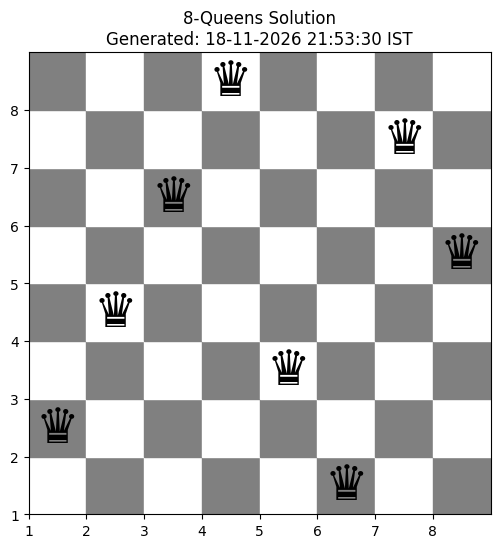

In [ ]:
import matplotlib.pyplot as plt
from datetime import datetime
from zoneinfo import ZoneInfo


# Check whether a queen can be safely placed
def is_safe(board, col, row):
    for c in range(col):
        # Check same row or diagonal
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False

    return True


# Solve N-Queens using backtracking
def solve(n):
    board = [-1] * n
    solutions = []
    nodes = 0

    def backtrack(col):
        nonlocal nodes

        # All queens have been placed
        if col == n:
            solutions.append(tuple(board))
            return

        # Try every row in the current column
        for row in range(n):
            nodes += 1

            if is_safe(board, col, row):
                board[col] = row
                backtrack(col + 1)
                board[col] = -1  # Backtrack

    backtrack(0)

    return solutions, nodes


# Draw the chessboard
def draw_board(solution):
    n = len(solution)

    # Get current date and time in Indian Standard Time
    current_datetime = datetime.now(
        ZoneInfo("Asia/Kolkata")
    ).strftime("%d-%m-%Y %H:%M:%S IST")

    # Create chessboard
    fig, ax = plt.subplots(figsize=(6, 6))

    # Draw squares
    for row in range(n):
        for col in range(n):

            color = "white" if (row + col) % 2 == 0 else "gray"

            ax.add_patch(
                plt.Rectangle(
                    (col, row),
                    1,
                    1,
                    color=color
                )
            )

    # Draw queens
    for col, row in enumerate(solution):
        ax.text(
            col + 0.5,
            row + 0.5,
            "♛",
            fontsize=35,
            ha="center",
            va="center"
        )

    # Board settings
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))

    ax.set_xticklabels(range(1, n + 1))
    ax.set_yticklabels(range(1, n + 1))

    ax.set_aspect("equal")

    # Display title with IST date and time
    ax.set_title(
        f"{n}-Queens Solution\n"
        f"Generated: {current_datetime}"
    )

    plt.show()


# Solve the 8-Queens problem
sols, nodes = solve(8)

# Print results
print(len(sols), "solutions,", nodes, "nodes visited")

# Display the fifth solution
draw_board(sols[4])